In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [3]:
# Replace with the actual path if needed
df = pd.read_csv("/content/Data_file - data_file Predicting_Property_Prize .csv")
df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600,NEAR BAY
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500,NEAR BAY
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100,NEAR BAY
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300,NEAR BAY
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200,NEAR BAY


In [5]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [6]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  int64  
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(4), int64(5), object(1)
memory usage: 1.6+ MB


,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [ ]:
# Fill missing bedrooms with median (or use imputation in pipeline later)
df['total_bedrooms'].fillna(df['total_bedrooms'].median())

,total_bedrooms
0,129.0
1,1106.0
2,190.0
3,235.0
4,280.0
...,...
20635,374.0
20636,150.0
20637,485.0
20638,409.0


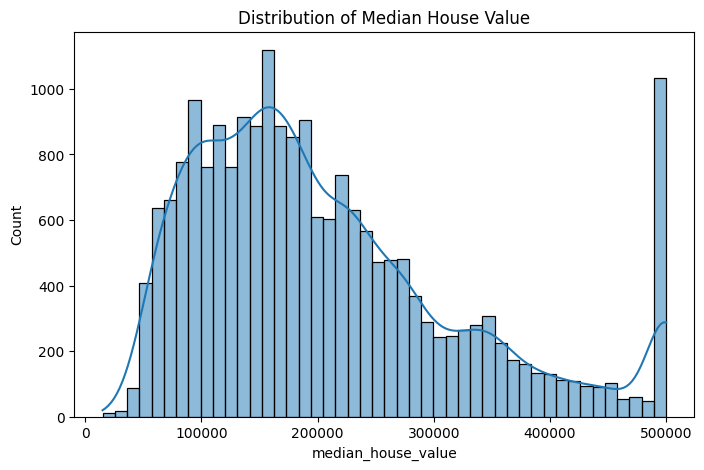

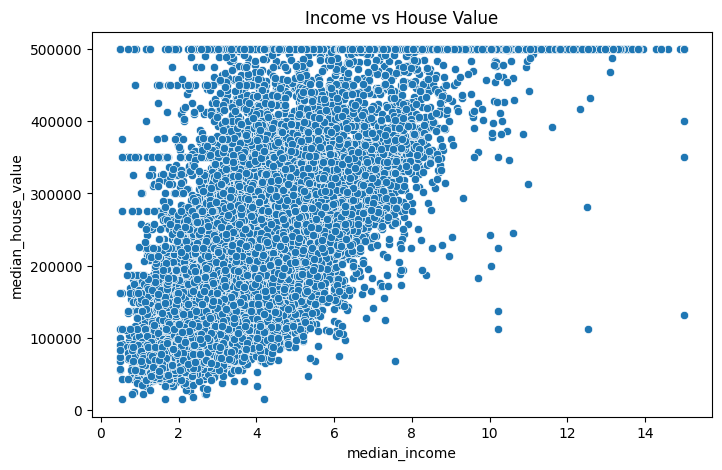

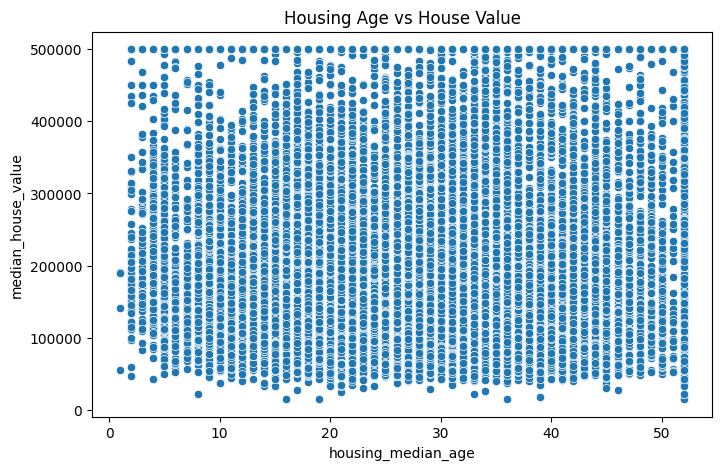

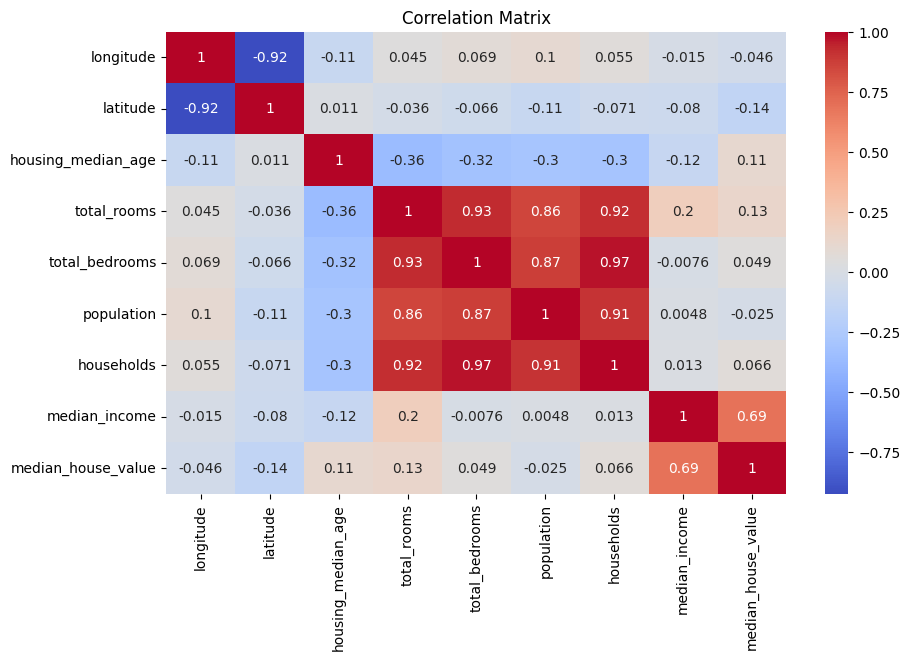

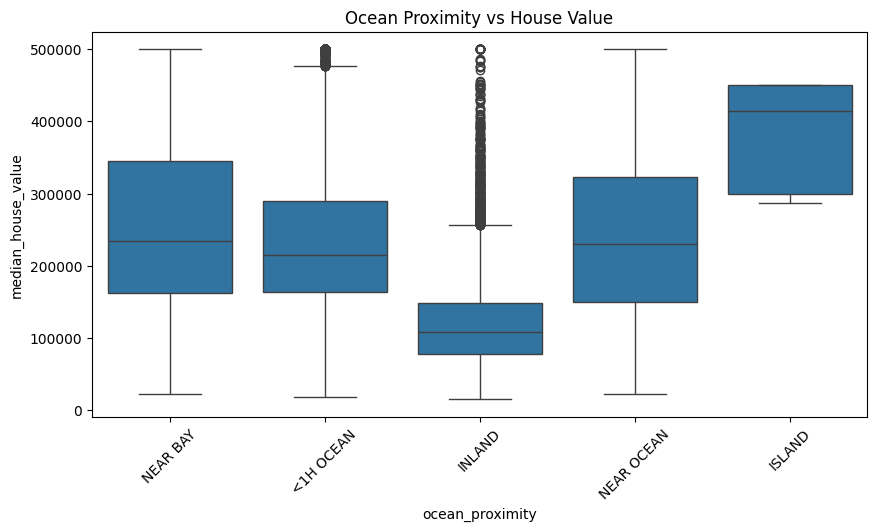

In [8]:
# Histogram of median house value
plt.figure(figsize=(8,5))
sns.histplot(df['median_house_value'], kde=True)
plt.title("Distribution of Median House Value")
plt.show()

# Scatter plots
plt.figure(figsize=(8,5))
sns.scatterplot(x='median_income', y='median_house_value', data=df)
plt.title("Income vs House Value")
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(x='housing_median_age', y='median_house_value', data=df)
plt.title("Housing Age vs House Value")
plt.show()

# Correlation heatmap
# plt.figure(figsize=(10,6))
# sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
# plt.title("Correlation Matrix")
# plt.show()

# Select only numeric columns
numeric_df = df.select_dtypes(include=['number'])

# Correlation heatmap
plt.figure(figsize=(10,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()


# Boxplot for ocean proximity
plt.figure(figsize=(10,5))
sns.boxplot(x='ocean_proximity', y='median_house_value', data=df)
plt.xticks(rotation=45)
plt.title("Ocean Proximity vs House Value")
plt.show()


In [9]:
# Features and target
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [10]:
# Use only 'median_income' as predictor
X_income = X_train[['median_income']]
X_income_test = X_test[['median_income']]

# Train the model
simple_model = LinearRegression()
simple_model.fit(X_income, y_train)

# Predictions
y_pred_simple = simple_model.predict(X_income_test)

# Evaluation
mse_simple = mean_squared_error(y_test, y_pred_simple)
rmse_simple = np.sqrt(mse_simple)
r2_simple = r2_score(y_test, y_pred_simple)

print("Simple Linear Regression:")
print(f"MSE: {mse_simple:.2f}")
print(f"RMSE: {rmse_simple:.2f}")
print(f"R²: {r2_simple:.4f}")


Simple Linear Regression:
MSE: 7091157771.77
RMSE: 84209.01
R²: 0.4589


In [11]:
# Multiple Linear Regression (with preprocessing pipeline)

# Define Columns

numeric_features = ['longitude', 'latitude', 'housing_median_age',
                    'total_rooms', 'total_bedrooms', 'population',
                    'households', 'median_income']

categorical_features = ['ocean_proximity']


In [12]:
# Create Preprocessing Pipeline

numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])


In [13]:
#Build Full Pipeline

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [14]:
# Train the Pipeline python Copy code


pipeline.fit(X_train, y_train)

# Predictions
y_pred_multi = pipeline.predict(X_test)

# Evaluation
mse_multi = mean_squared_error(y_test, y_pred_multi)
rmse_multi = np.sqrt(mse_multi)
r2_multi = r2_score(y_test, y_pred_multi)

print("Multiple Linear Regression:")
print(f"MSE: {mse_multi:.2f}")
print(f"RMSE: {rmse_multi:.2f}")
print(f"R²: {r2_multi:.4f}")

Multiple Linear Regression:
MSE: 4908476721.16
RMSE: 70060.52
R²: 0.6254


In [15]:
# Compare Models

comparison = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'MSE': [mse_simple, mse_multi],
    'RMSE': [rmse_simple, rmse_multi],
    'R²': [r2_simple, r2_multi]
})

comparison


,Model,MSE,RMSE,R²
0,Simple Linear Regression,7.091158e+09,84209.012414,0.458859
1,Multiple Linear Regression,4.908477e+09,70060.521845,0.625424


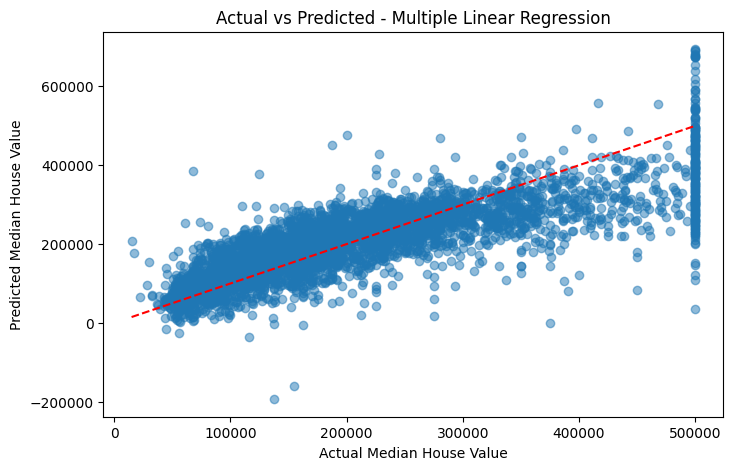

In [16]:
# Visualize Predictions

plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred_multi, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs Predicted - Multiple Linear Regression")
plt.show()


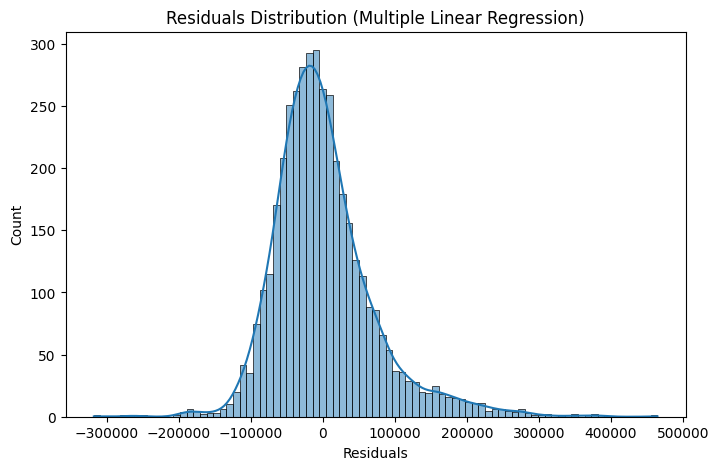

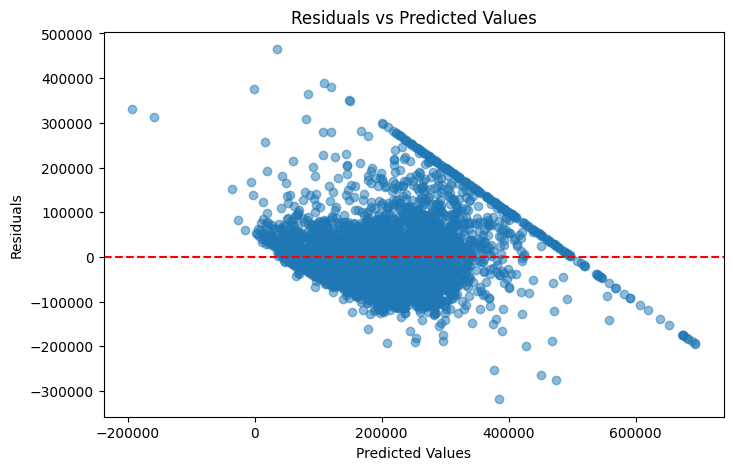

In [17]:
# Residuals for multiple linear regression
residuals = y_test - y_pred_multi

plt.figure(figsize=(8,5))
sns.histplot(residuals, kde=True)
plt.title("Residuals Distribution (Multiple Linear Regression)")
plt.xlabel("Residuals")
plt.show()

# Residuals vs Predicted
plt.figure(figsize=(8,5))
plt.scatter(y_pred_multi, residuals, alpha=0.5)
plt.axhline(0, color='r', linestyle='--')
plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.show()


In [18]:
import joblib

# Save the pipeline to a file
joblib.dump(pipeline, 'final_house_price_model.pkl')
print("Model saved as final_house_price_model.pkl")


Model saved as final_house_price_model.pkl


In [19]:
loaded_model = joblib.load('final_house_price_model.pkl')


In [21]:
! pip install streamlit


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 61.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 8.1 MB/s eta 0:00:00


In [22]:
import streamlit as st
import joblib
import pandas as pd

model = joblib.load("final_house_price_model.pkl")

st.title("California House Price Prediction")

# User input
longitude = st.number_input("Longitude", value=-122.23)
latitude = st.number_input("Latitude", value=37.88)
housing_median_age = st.number_input("Median Age", value=41)
total_rooms = st.number_input("Total Rooms", value=880)
total_bedrooms = st.number_input("Total Bedrooms", value=129)
population = st.number_input("Population", value=322)
households = st.number_input("Households", value=126)
median_income = st.number_input("Median Income", value=8.3252)
ocean_proximity = st.selectbox("Ocean Proximity", ['NEAR BAY', 'INLAND', 'NEAR OCEAN', 'ISLAND', '<1H OCEAN'])

# Predict
if st.button("Predict"):
    data = pd.DataFrame([{
        'longitude': longitude,
        'latitude': latitude,
        'housing_median_age': housing_median_age,
        'total_rooms': total_rooms,
        'total_bedrooms': total_bedrooms,
        'population': population,
        'households': households,
        'median_income': median_income,
        'ocean_proximity': ocean_proximity
    }])

    prediction = model.predict(data)[0]
    st.success(f"Predicted House Value: ${prediction:,.2f}")


2025-05-28 14:39:34.333 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-28 14:39:34.520 
  command:

    streamlit run /usr/local/lib/python3.11/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2025-05-28 14:39:34.527 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-28 14:39:34.528 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-28 14:39:34.529 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-28 14:39:34.530 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-28 14:39:34.531 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-28 14:39:34.532 Session state does not 

In [27]:
!streamlit run app.py





  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.169.108.190:8501

  Stopping...
^C
